### Moving Average Smoothing Layer

In [1]:
from pathlib import Path
import sys

def find_project_root():
    here = Path.cwd()
    for p in [here, *here.parents]:
        if (p / "utils").exists() and (p / "models").exists():
            return p
    for p in [here, *here.parents]:
        if any((p / m).exists() for m in (".git", "requirements.txt", "pyproject.toml")):
            return p
    return here

PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

%load_ext autoreload
%autoreload 2

In [2]:
# Import necessary libraries
import os
import sys
import matplotlib.pyplot as plt
import torch
import numpy as np
import torch.nn as nn
import pandas as pd
from utils.reproducibility_utils import seed_everything
from utils.data_loading import load_data, load_test_data, feature_names

# Set the plotting style for better-looking visualizations
plt.style.use('seaborn-v0_8')

In [3]:
# Set a seed for reproducibility
seed_everything(42)

In [4]:
print("Loading train data...")
train_dataloader, val_dataloader, pipeline = load_data(
    train_path = "../../datasets_challenge/train",
    train_ratio = 0.98,  # 🔥 FIX: Was None! Must be 0.98 for 98/2 split
    batchsize = 64,
    columns_to_drop = ["sideSlip", "vyCG", "time", "longitude","latitude"],
    sequence_length = 20,
    threshold = True,
    threshold_value = 3.0,
    threshold_column = "vxCG",
    target = "sideSlip",
    scaling = True,
    seed = 42,
)

print(f"✅ Data loaded")
print(f"   Train batches: {len(train_dataloader)}")
print(f"   Val batches: {len(val_dataloader) if val_dataloader else 0}")

Loading train data...
../../datasets_challenge/train\train_part_001.csv
../../datasets_challenge/train\train_part_002.csv
../../datasets_challenge/train\train_part_003.csv
../../datasets_challenge/train\train_part_004.csv
../../datasets_challenge/train\train_part_005.csv
../../datasets_challenge/train\train_part_006.csv
../../datasets_challenge/train\train_part_007.csv
../../datasets_challenge/train\train_part_008.csv
../../datasets_challenge/train\train_part_009.csv
../../datasets_challenge/train\train_part_010.csv
../../datasets_challenge/train\train_part_011.csv
../../datasets_challenge/train\train_part_012.csv
../../datasets_challenge/train\train_part_013.csv
../../datasets_challenge/train\train_part_014.csv
../../datasets_challenge/train\train_part_015.csv
../../datasets_challenge/train\train_part_016.csv
../../datasets_challenge/train\train_part_017.csv
../../datasets_challenge/train\train_part_018.csv
../../datasets_challenge/train\train_part_019.csv
../../datasets_challenge/tra

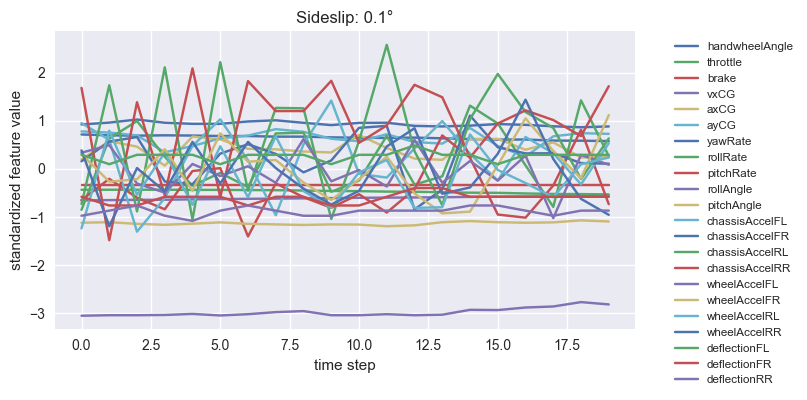

In [5]:
# Get one batch to check dimensions
X, y = next(iter(train_dataloader))

plt.figure(figsize=(8,4))
plt.plot(X[0,:,:], label=feature_names)
plt.title("Sideslip: "+str(round(y[0].item(),2))+"°")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize='small')
plt.tight_layout()
plt.xlabel("time step")
plt.ylabel("standardized feature value")
plt.show()

### Moving Average Module

In [6]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class MovingAverage(nn.Module):
    def __init__(self, kernel_size=3):
        super().__init__()
        self.k = kernel_size

        # Fixed averaging kernel
        kernel = torch.ones(kernel_size) / kernel_size
        self.register_buffer("kernel", kernel.view(1, 1, -1))  
        # shape: (out_channels=1, in_channels=1, kernel_size)
    
    def forward(self, x):
        # x shape: (batch, 1)

        pad = self.k // 2

        # Pad on left and right
        # replicate padding = extend edge values
        x_padded = F.pad(x, (pad, pad), mode="replicate")  # shape: (batch, 1+2pad)

        # Conv1d expects: (batch, channels=1, length)
        x_conv = F.conv1d(
            x_padded.unsqueeze(1),   # (batch, 1, length)
            self.kernel              # (1,1,k)
        )

        return x_conv.squeeze(1)     # back to (batch,1)


In [7]:
class RNNWithMovingAvg(nn.Module):
    def __init__(self, input_size, output_size=1, rnn_units=64, fc_units=64,
                 activation_fct=nn.ReLU(), kernel_size=5):
        super().__init__()

        self.rnn_layer = nn.RNN(
            input_size=input_size,
            hidden_size=rnn_units,
            num_layers=1,
            nonlinearity='relu',
            batch_first=True
        )

        self.fc = nn.Linear(rnn_units, fc_units)
        self.output_layer = nn.Linear(fc_units, output_size)

        # Add smoothing layer
        self.smoother = MovingAverage(kernel_size=kernel_size)

        self.activation_fct = activation_fct

    def forward(self, x):
        x, _ = self.rnn_layer(x)
        x = x[:, -1, :]                      # last timestep (batch, rnn_units)

        x = self.activation_fct(self.fc(x))
        x = self.output_layer(x)             # (batch,1)

        # Apply smoothing
        x = self.smoother(x)

        return x


In [8]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

input_size = X.shape[2]
rnn_units = 64
fc_units = 64
output_size = 1
lr = 0.0003

model = RNNWithMovingAvg(
    input_size=input_size,
    rnn_units=rnn_units,
    fc_units=fc_units,
    kernel_size=3  # try 3, 5, or 7
).to(device)

criterion = nn.L1Loss()
optimizer = torch.optim.Adam(model.parameters(), lr=lr)
print(f"Model parameters: {sum(p.numel() for p in model.parameters()):,}")

Using device: cpu
Model parameters: 9,857


In [9]:
# Training loop
num_epochs = 50
early_stop_thresh = 10
best_loss = np.inf
best_epoch = -1

train_curve = []
val_curve = []

print("\n" + "="*80)
print("🚀 STARTING TRAINING (WITH VALIDATION SPLIT)")
print("="*80)

for epoch in range(num_epochs):
    # TRAINING
    model.train()
    running_loss = 0
    
    for step, (x, y) in enumerate(train_dataloader):
        X, y = x.to(device), y.to(device).reshape([len(y), 1])
        
        optimizer.zero_grad()
        pred = model(X)
        train_loss = criterion(pred, y)
        running_loss += train_loss.item()
        train_loss.backward()
        optimizer.step()
    
    avg_train_loss = running_loss / (step + 1)
    train_curve.append(avg_train_loss)

    # VALIDATION
    if val_dataloader is not None:
        model.eval()
        running_val_loss = 0
        with torch.no_grad():
            for val_step, (x, y) in enumerate(val_dataloader):
                X_val, y_val = x.to(device), y.to(device).reshape([len(y), 1])
                val_loss = criterion(model(X_val), y_val)
                running_val_loss += val_loss.item()
        
        avg_val_loss = running_val_loss / (val_step + 1)
        val_curve.append(avg_val_loss)

        print(f"Epoch {epoch+1:2d}/{num_epochs} | Train: {avg_train_loss:.5f} | Val: {avg_val_loss:.5f}", end="")
        
        # EARLY STOPPING
        if avg_val_loss < best_loss:
            best_loss = avg_val_loss
            best_epoch = epoch
            # 🔥 FIX: Complete save dictionary
            torch.save({
                'epoch': epoch,
                'model_state_dict': model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'loss': best_loss,
                'train_loss': avg_train_loss,
                'val_loss': avg_val_loss
            }, 'best_model.pth')
            print(f" 💾 NEW BEST!")
        elif epoch - best_epoch > early_stop_thresh:
            print(f"\n⏹️  Early stopping at epoch {epoch+1}")
            break
        else:
            print("")
    else:
        print(f"⚠️  WARNING: No validation split! Training on 100%")
        print(f"Epoch {epoch+1}/{num_epochs} | Train: {avg_train_loss:.5f}")

# LOAD BEST MODEL
if best_epoch != -1:
    checkpoint = torch.load('best_model.pth', weights_only=True)
    model.load_state_dict(checkpoint['model_state_dict'])
    print(f"\n" + "="*80)
    print(f"✅ Best model from epoch {best_epoch+1} loaded")
    print(f"   Train Loss: {checkpoint.get('train_loss', 'N/A'):.5f}")
    print(f"   Val Loss:   {checkpoint.get('val_loss', best_loss):.5f}")
    print("="*80)
else:
    print("\n⚠️  No improvement found, using current model")


🚀 STARTING TRAINING (WITH VALIDATION SPLIT)
Epoch  1/50 | Train: 0.27533 | Val: 0.19839 💾 NEW BEST!
Epoch  2/50 | Train: 0.19148 | Val: 0.17614 💾 NEW BEST!
Epoch  3/50 | Train: 0.17596 | Val: 0.17812
Epoch  4/50 | Train: 0.16740 | Val: 0.16477 💾 NEW BEST!
Epoch  5/50 | Train: 0.16315 | Val: 0.15793 💾 NEW BEST!
Epoch  6/50 | Train: 0.15762 | Val: 0.15940
Epoch  7/50 | Train: 0.15525 | Val: 0.16125
Epoch  8/50 | Train: 0.15279 | Val: 0.14956 💾 NEW BEST!
Epoch  9/50 | Train: 0.15058 | Val: 0.15312
Epoch 10/50 | Train: 0.14887 | Val: 0.14894 💾 NEW BEST!
Epoch 11/50 | Train: 0.14782 | Val: 0.14940
Epoch 12/50 | Train: 0.14524 | Val: 0.13927 💾 NEW BEST!
Epoch 13/50 | Train: 0.14450 | Val: 0.14312
Epoch 14/50 | Train: 0.14362 | Val: 0.14617
Epoch 15/50 | Train: 0.14226 | Val: 0.14440
Epoch 16/50 | Train: 0.14102 | Val: 0.14764
Epoch 17/50 | Train: 0.13948 | Val: 0.14847
Epoch 18/50 | Train: 0.13847 | Val: 0.13709 💾 NEW BEST!
Epoch 19/50 | Train: 0.13706 | Val: 0.14033
Epoch 20/50 | Train: 0.

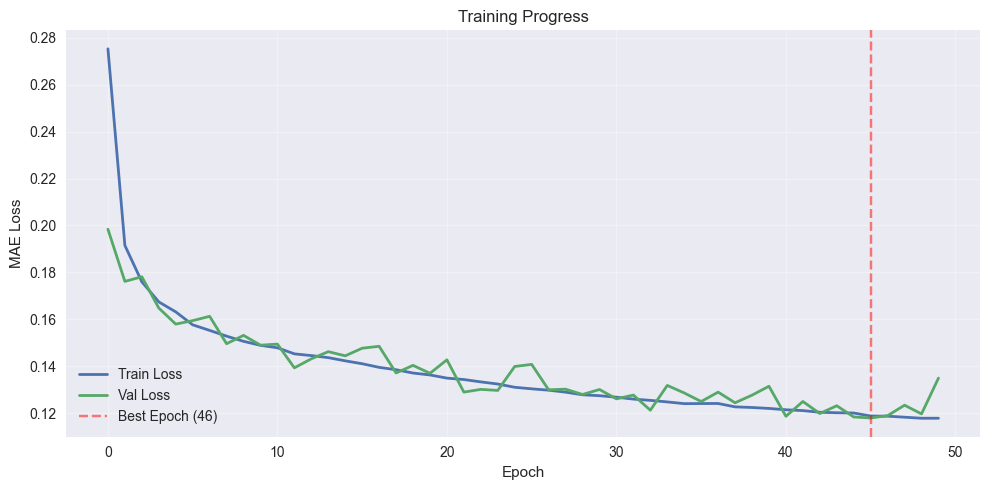

Final train loss: 0.11779
Final val loss:   0.13489
Best val loss:    0.11788 (epoch 46)


In [10]:
# Plot training curves
plt.figure(figsize=(10, 5))
plt.plot(train_curve, label='Train Loss', linewidth=2)
if val_curve:
    plt.plot(val_curve, label='Val Loss', linewidth=2)
    if best_epoch != -1:
        plt.axvline(x=best_epoch, color='r', linestyle='--', alpha=0.5, label=f'Best Epoch ({best_epoch+1})')
plt.xlabel('Epoch')
plt.ylabel('MAE Loss')
plt.title('Training Progress')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Final train loss: {train_curve[-1]:.5f}")
if val_curve:
    print(f"Final val loss:   {val_curve[-1]:.5f}")
    print(f"Best val loss:    {best_loss:.5f} (epoch {best_epoch+1})")

In [11]:
# Load complete training data for visualization
train_dataloader_unshuffled = load_test_data(
    test_path="../../datasets_challenge/train",
    batchsize=64,
    pipeline=pipeline,
    load_anonymized_data=False
)

../../datasets_challenge/train\train_part_001.csv
../../datasets_challenge/train\train_part_002.csv
../../datasets_challenge/train\train_part_003.csv
../../datasets_challenge/train\train_part_004.csv
../../datasets_challenge/train\train_part_005.csv
../../datasets_challenge/train\train_part_006.csv
../../datasets_challenge/train\train_part_007.csv
../../datasets_challenge/train\train_part_008.csv
../../datasets_challenge/train\train_part_009.csv
../../datasets_challenge/train\train_part_010.csv
../../datasets_challenge/train\train_part_011.csv
../../datasets_challenge/train\train_part_012.csv
../../datasets_challenge/train\train_part_013.csv
../../datasets_challenge/train\train_part_014.csv
../../datasets_challenge/train\train_part_015.csv
../../datasets_challenge/train\train_part_016.csv
../../datasets_challenge/train\train_part_017.csv
../../datasets_challenge/train\train_part_018.csv
../../datasets_challenge/train\train_part_019.csv
../../datasets_challenge/train\train_part_020.csv


In [12]:
import plotly.graph_objects as go

model.eval()
total_loss = 0
preds = []
ground_truths = []

with torch.no_grad():
    for step, (x, y) in enumerate(train_dataloader_unshuffled):
        X, y = x.to(device), y.to(device).reshape([len(y), 1])
        pred = model(X)
        loss = criterion(pred, y)
        total_loss += loss.item()
        preds.append(pred.reshape(-1).cpu().numpy())
        ground_truths.append(y.reshape(-1).cpu().numpy())

    print(f"Training set MAE: {total_loss/(step+1):.5f}")
    
    ground_truths = np.concatenate(ground_truths)
    preds = np.concatenate(preds)

fig = go.Figure()
fig.add_trace(go.Scatter(y=ground_truths, mode='lines', name='truth', line=dict(color='blue')))
fig.add_trace(go.Scatter(y=preds.flatten(), mode='lines', name='pred', line=dict(color='red'), opacity=0.8))
fig.update_layout(
    title='Ground Truth vs Predictions (Training Set)',
    xaxis_title='Sample Index',
    yaxis_title='Sideslip Angle (degrees)',
    width=1200,
    height=500
)
fig.show()



Training set MAE: 0.11792


In [13]:
print("\nLoading test data...")
test_dataloader = load_test_data(
    test_path = "../../datasets_challenge/test",
    batchsize = 64,
    pipeline = pipeline, 
    load_anonymized_data=True
)


Loading test data...
../../datasets_challenge/test\test_part_001.csv
../../datasets_challenge/test\test_part_002.csv
../../datasets_challenge/test\test_part_003.csv
../../datasets_challenge/test\test_part_004.csv
../../datasets_challenge/test\test_part_005.csv
../../datasets_challenge/test\test_part_006.csv
../../datasets_challenge/test\test_part_007.csv
../../datasets_challenge/test\test_part_008.csv
../../datasets_challenge/test\test_part_009.csv
../../datasets_challenge/test\test_part_010.csv
../../datasets_challenge/test\test_part_011.csv


In [14]:
# Generate test predictions
model.eval()
test_preds = []

with torch.no_grad():
    for step, (x, y) in enumerate(test_dataloader):
        X = x.to(device)
        pred = model(X)
        test_preds.append(pred.reshape(-1).cpu().numpy())

test_preds = np.concatenate(test_preds)
print(f"Test predictions: {len(test_preds)} samples")
print(f"Range: [{test_preds.min():.3f}, {test_preds.max():.3f}]")
print(f"Mean:  {test_preds.mean():.3f}")
print(f"Std:   {test_preds.std():.3f}")

Test predictions: 49328 samples
Range: [-8.997, 10.445]
Mean:  0.031
Std:   1.457


In [16]:
# Save predictions
y_pred = pd.DataFrame({
    "id": range(len(test_preds)),
    "predicted_sideslip": test_preds
})

y_pred.to_csv("predictions_Moving_Average2.csv", index=False)

print(f"\n" + "="*80)
print(f"✅ Predictions saved to 'predictions_Moving_Average2.csv'")
print(f"   Total samples: {len(test_preds)}")
print(f"   Ready for Kaggle submission!")
print(f"   Expected score: ~0.29° (with proper train/val split)")
print("="*80)


✅ Predictions saved to 'predictions_Moving_Average2.csv'
   Total samples: 49328
   Ready for Kaggle submission!
   Expected score: ~0.29° (with proper train/val split)
